# Seed sensitivity of the `cgan_cnn_2d` baseline on Beams2D

Muhammad Usman Altaf, 25 November 2026

This notebook asks how much the outcome of training the EngiOpt `cgan_cnn_2d` baseline on `beams2d` depends on the random seed, and whether the two learning rates explain it. It relates to EngiOpt issue 81, "Improve the performance of existing simple baseline models".

It has two parts.

1. **Published checkpoints.** A reading of the metrics that are published next to the checkpoints in `IDEALLab/engiopt-cgan-cnn-2d`. Nothing is trained in this part.
2. **New runs.** 40 training runs that test what part 1 suggests: four pairs of learning rates, ten seeds each, everything else held fixed. The training script is the unmodified one from EngiOpt.

**Summary**

- The one published configuration that has 11 seeds ends with MMD above 0.1 in 6 of them. My 10 runs of the same configuration give 6 of 10.
- With the generator learning rate at 1e-3 and the discriminator at 1e-4, all 10 seeds end between MMD 0.017 and 0.029.
- With the script's current defaults (generator 1e-4, discriminator 4e-4), 8 of 10 seeds end above 0.1, and 7 of those have collapsed: the generator draws almost the same image for every condition.
- The learning rates do not fix everything. In the stable setting the constraint violation rate still ranges from 0.12 to 0.86 across seeds.

Everything below reads from `data/`. Rerunning the notebook needs only pandas, scipy and matplotlib.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import fisher_exact, mannwhitneyu

DATA = Path("data")
MMD_THRESHOLD = 0.1  # a run counts as "off the data" above this; see the limits at the end

INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": INK_2, "ytick.color": INK_2, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

## Part 1. What the published checkpoints already show

The Hugging Face repository holds one folder per configuration and seed, each with a `run_config.json` and a `metrics.json`. `code/pull_published.py` downloads those two files for every `beams2d` checkpoint into `data/published_checkpoints.json`.

In [2]:
raw = json.loads((DATA / "published_checkpoints.json").read_text(encoding="utf-8"))
pub = pd.DataFrame([
    {
        "config": r["cfg"],
        "seed": int(r["seed"].split("_")[1]),
        **{k: r["run_config"][k] for k in ("lr_gen", "lr_disc", "n_epochs", "batch_size", "latent_dim")},
        "mmd": r["metrics"]["metrics"]["mmd"],
        "viol": r["metrics"]["metrics"]["viol"],
        "n_samples": r["metrics"]["metrics"]["n_samples"],
        "spec_version": r["metrics"]["metrics"]["spec_version"],
        "evaluated_at": r["metrics"]["metrics"]["evaluated_at"][:10],
    }
    for r in raw
])
seeds_per_config = pub.groupby("config")["seed"].nunique()
print(f"{len(pub)} evaluated checkpoints, {pub['config'].nunique()} configurations")
print("seeds per configuration:", seeds_per_config.value_counts().sort_index().to_dict())
print("samples per evaluation:", sorted(int(n) for n in pub["n_samples"].unique()), "| spec version:", sorted(pub["spec_version"].unique()),
      "| evaluated:", pub["evaluated_at"].min(), "to", pub["evaluated_at"].max())

46 evaluated checkpoints, 36 configurations
seeds per configuration: {1: 35, 11: 1}
samples per evaluation: [50] | spec version: ['v2'] | evaluated: 2026-08-12 to 2026-08-13


### The one configuration with more than one seed

All configurations but one were trained with seed 42 only. The exception has 11 seeds.

In [3]:
multi = seeds_per_config.idxmax()
eleven = pub[pub["config"] == multi].sort_values("mmd").reset_index(drop=True)
print(multi, eleven.iloc[0][["lr_gen", "lr_disc", "n_epochs", "batch_size", "latent_dim"]].to_dict())
print(f"runs with MMD above {MMD_THRESHOLD}: {(eleven['mmd'] > MMD_THRESHOLD).sum()} of {len(eleven)}")
eleven[["seed", "mmd", "viol"]].rename(columns={"mmd": "MMD", "viol": "violation rate"})

cfg_825831f6 {'lr_gen': 0.0003, 'lr_disc': 0.0003, 'n_epochs': 200, 'batch_size': 32, 'latent_dim': 32}
runs with MMD above 0.1: 6 of 11


,seed,MMD,violation rate
0,4,0.012,0.180
1,3,0.013,0.780
2,42,0.013,0.380
3,2,0.015,0.340
4,9,0.059,0.760
5,6,0.150,0.780
6,10,0.514,0.880
7,1,0.532,0.920
8,5,0.737,0.980
9,7,0.773,0.840


The outcomes are split. A run lands either near 0.01 to 0.06 or far above 0.1, with one run in between. Seed 42, the seed used for every other configuration, is one of the good ones.

### Is the difference between configurations larger than the difference between seeds?

If one configuration can land anywhere from 0.012 to 0.81 depending on the seed, then a single-seed result for another configuration only tells us something if it falls outside that range.

In [4]:
single = pub[pub["seed"] == 42]
rows = []
for metric, label in (("mmd", "MMD"), ("viol", "Violation rate")):
    lo, hi = eleven[metric].min(), eleven[metric].max()
    outside = ((single[metric] < lo) | (single[metric] > hi)).sum()
    rows.append({
        "metric": label,
        "range over 11 seeds of one configuration": f"{lo:.3g} to {hi:.3g}",
        f"range over {len(single)} configurations (seed 42)": f"{single[metric].min():.3g} to {single[metric].max():.3g}",
        "configurations outside the seed range": f"{outside} of {len(single)}",
    })
pd.DataFrame(rows).set_index("metric")

,range over 11 seeds of one configuration,range over 36 configurations (seed 42),configurations outside the seed range
metric,,,
MMD,0.0115 to 0.812,0.00851 to 0.844,4 of 36
Violation rate,0.18 to 0.98,0.22 to 1,1 of 36


The two ranges are about the same size. Ranking the configurations one by one from a single seed each would mostly rank luck.

### The learning rates still show through

The sweep contains a full 2 by 2 grid over the generator and discriminator learning rates (1e-4 and 1e-3). Each cell holds eight configurations that differ in epochs, batch size and latent size. Treating those eight as rough replicates:

In [5]:
grid = single[single["lr_gen"].isin([1e-4, 1e-3]) & single["lr_disc"].isin([1e-4, 1e-3])].copy()
grid["above"] = grid["mmd"] > MMD_THRESHOLD
cells = (grid.groupby(["lr_gen", "lr_disc"])
         .agg(runs=("mmd", "size"), above=("above", "sum"), median_mmd=("mmd", "median"), median_viol=("viol", "median"))
         .reset_index().sort_values("median_mmd"))
cells["lr_gen"] = cells["lr_gen"].map("{:g}".format)
cells["lr_disc"] = cells["lr_disc"].map("{:g}".format)
display(cells.rename(columns={"lr_gen": "generator lr", "lr_disc": "discriminator lr", "above": f"MMD above {MMD_THRESHOLD}",
                              "median_mmd": "median MMD", "median_viol": "median violation rate"}).set_index(["generator lr", "discriminator lr"]))

slow_d, fast_d = grid[grid["lr_disc"] == 1e-4], grid[grid["lr_disc"] == 1e-3]
p_disc = fisher_exact([[slow_d["above"].sum(), (~slow_d["above"]).sum()], [fast_d["above"].sum(), (~fast_d["above"]).sum()]])[1]
best = grid[(grid["lr_gen"] == 1e-3) & (grid["lr_disc"] == 1e-4)]
n_bad_11 = int((eleven["mmd"] > MMD_THRESHOLD).sum())
p_best = fisher_exact([[best["above"].sum(), (~best["above"]).sum()], [n_bad_11, len(eleven) - n_bad_11]])[1]
print(f"discriminator lr 1e-4: {slow_d['above'].sum()} of {len(slow_d)} above the threshold; "
      f"1e-3: {fast_d['above'].sum()} of {len(fast_d)} (Fisher exact, two-sided, p = {p_disc:.3f})")
print(f"generator 1e-3 with discriminator 1e-4: {best['above'].sum()} of {len(best)}, "
      f"against {n_bad_11} of {len(eleven)} for the 11-seed configuration (p = {p_best:.3f})")

runs  MMD above 0.1  median MMD  \
generator lr discriminator lr                                    
0.001        0.0001               8              0       0.015   
0.0001       0.0001               8              2       0.045   
             0.001                8              6       0.123   
0.001        0.001                8              5       0.376   

                               median violation rate  
generator lr discriminator lr                         
0.001        0.0001                            0.340  
0.0001       0.0001                            0.580  
             0.001                             0.760  
0.001        0.001                             0.840

discriminator lr 1e-4: 2 of 16 above the threshold; 1e-3: 11 of 16 (Fisher exact, two-sided, p = 0.003)
generator 1e-3 with discriminator 1e-4: 0 of 8, against 6 of 11 for the 11-seed configuration (p = 0.018)


A slower discriminator goes with fewer bad runs, and the cell with the generator ten times faster than the discriminator has none. The eight configurations in a cell are not eight seeds, so this is a hint and not a result.

One more observation: the training script's current defaults are a generator learning rate of 1e-4 and a discriminator learning rate of 4e-4. No published checkpoint uses that pair, and it sits on the side of the grid where the discriminator is the faster of the two.

**What part 1 predicts.** Trained with several seeds each, (a) the script defaults should fail often, (b) the 11-seed configuration should fail about half the time, and (c) generator 1e-3 with discriminator 1e-4 should rarely fail. Part 2 tests this.

## Part 2. New runs: four learning-rate pairs, ten seeds each

| Arm | Generator lr | Discriminator lr | Why it is here |
|---|---|---|---|
| Script default | 1e-4 | 4e-4 | the defaults in `cgan_cnn_2d.py` |
| Published 11-seed configuration | 3e-4 | 3e-4 | the configuration from part 1 |
| Generator faster | 1e-3 | 1e-4 | the best cell of the published grid |
| Discriminator faster | 1e-4 | 1e-3 | the mirror image, as a control |

Fixed in every run: `beams2d`, 200 epochs, batch size 32, latent size 32, seeds 1 to 10. Training uses the unmodified script from EngiOpt at commit `7a98ba5`. That was `main` until the metrics-suite merge of 24 November 2026, which does not change the training script or its default learning rates. Scoring uses `python -m engiopt.evaluate` from the same commit, with spec `beams2d/v1` and 50 samples per run.

The published metrics in part 1 carry spec version `v2`, and mine carry `v1`. I have not yet rescored my runs with the newer evaluation code, so I compare arms with each other inside each part and do not compare absolute values between the parts.

In [6]:
ARMS = {  # file key -> (label, generator lr, discriminator lr, colour, marker)
    "default_g1e-4_d4e-4": ("Script default", 1e-4, 4e-4, "#2a78d6", "o"),
    "published11_g3e-4_d3e-4": ("Published 11-seed configuration", 3e-4, 3e-4, "#eb6834", "s"),
    "stable_g1e-3_d1e-4": ("Generator faster", 1e-3, 1e-4, "#1baf7a", "^"),
    "discfast_g1e-4_d1e-3": ("Discriminator faster", 1e-4, 1e-3, "#eda100", "D"),
}
LABEL = {k: v[0] for k, v in ARMS.items()}
ORDER = [v[0] for v in ARMS.values()]

runs = pd.concat([pd.read_csv(DATA / f"results_{key}.csv").assign(key=key) for key in ARMS], ignore_index=True)
spread = pd.read_csv(DATA / "sample_spread.csv")
REF_SPREAD = float(spread.loc[spread["arm"] == "reference", "sample_spread"].iloc[0])
spread = spread[spread["arm"] != "reference"].astype({"seed": int}).rename(columns={"arm": "key"})
runs = runs.merge(spread[["key", "seed", "sample_spread"]], on=["key", "seed"], validate="one_to_one")
runs["arm"] = runs["key"].map(LABEL)
print(len(runs), "runs | code", runs["code_version"].unique().tolist(), "| engibench", runs["engibench_version"].unique().tolist(),
      "| spec", runs["spec_version"].unique().tolist(), "| samples per run", runs["n_samples"].unique().tolist())

runs.pivot(index="seed", columns="arm", values="mmd")[ORDER].rename_axis(columns="MMD by seed")

40 runs | code ['0.0.1+7a98ba52107c'] | engibench ['0.2.0'] | spec ['v1'] | samples per run [50]


MMD by seed,Script default,Published 11-seed configuration,Generator faster,Discriminator faster
seed,,,,
1,0.780,0.254,0.027,0.667
2,0.665,0.556,0.017,0.801
3,0.039,0.040,0.021,0.087
4,0.811,0.025,0.029,0.049
5,0.542,0.089,0.018,0.706
6,0.078,0.190,0.027,0.077
7,0.107,0.034,0.022,0.110
8,0.850,0.259,0.025,0.823
9,0.924,0.864,0.022,0.060


### How many runs go wrong, per arm

In [7]:
runs["above"] = runs["mmd"] > MMD_THRESHOLD
summary = (runs.groupby("arm")
           .agg(seeds=("seed", "size"), above=("above", "sum"), median_mmd=("mmd", "median"),
                min_mmd=("mmd", "min"), max_mmd=("mmd", "max"), median_viol=("viol", "median"),
                min_viol=("viol", "min"), max_viol=("viol", "max"))
           .loc[ORDER])
summary.rename(columns={"above": f"MMD above {MMD_THRESHOLD}", "median_mmd": "median MMD", "min_mmd": "min MMD", "max_mmd": "max MMD",
                        "median_viol": "median violation rate", "min_viol": "min violation", "max_viol": "max violation"})

,seeds,MMD above 0.1,median MMD,min MMD,max MMD,median violation rate,min violation,max violation
arm,,,,,,,,
Script default,10,8,0.722,0.039,0.924,0.860,0.560,0.960
Published 11-seed configuration,10,6,0.222,0.025,0.864,0.830,0.260,0.960
Generator faster,10,0,0.022,0.017,0.029,0.330,0.120,0.860
Discriminator faster,10,5,0.099,0.030,0.823,0.730,0.380,0.980


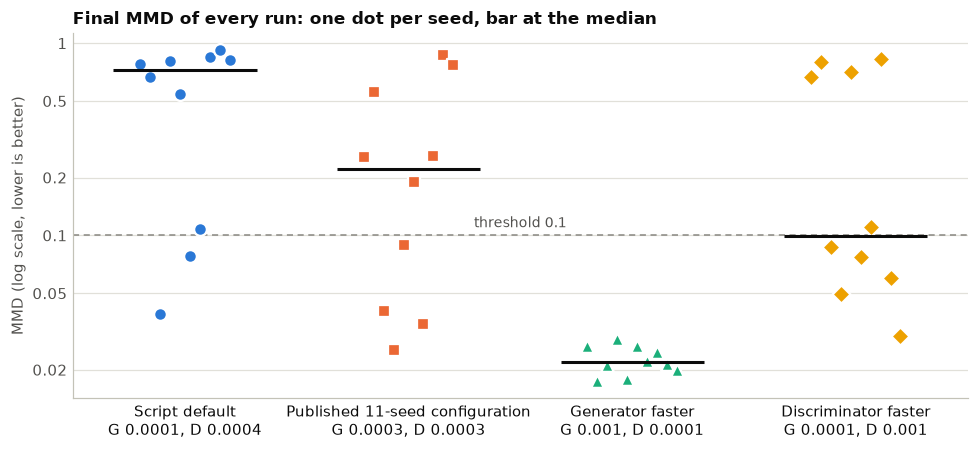

In [8]:
def strip(ax, column, ylabel, log=False):
    # One dot per seed, one column of dots per arm. The short bar marks the median.
    for i, (key, (label, _, _, colour, marker)) in enumerate(ARMS.items()):
        values = runs.loc[runs["key"] == key].sort_values("seed")[column].to_numpy()
        x = i + np.linspace(-0.2, 0.2, len(values))
        ax.scatter(x, values, s=70, color=colour, marker=marker, edgecolor="white", linewidth=1.5, zorder=3)
        ax.hlines(np.median(values), i - 0.32, i + 0.32, color=INK, linewidth=2, zorder=4)
    if log:
        ax.set_yscale("log")
    ax.set_xticks(range(len(ARMS)))
    ax.set_xticklabels([f"{label}\nG {g:g}, D {d:g}" for label, g, d, _, _ in ARMS.values()], color=INK)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y")
    ax.tick_params(length=0)


fig, ax = plt.subplots(figsize=(9, 4.2))
strip(ax, "mmd", "MMD (log scale, lower is better)", log=True)
ax.axhline(MMD_THRESHOLD, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
ax.text(1.5, MMD_THRESHOLD * 1.06, f"threshold {MMD_THRESHOLD}", color=INK_2, ha="center", va="bottom", fontsize=9)
ax.set_yticks([0.02, 0.05, 0.1, 0.2, 0.5, 1.0])
ax.set_yticklabels(["0.02", "0.05", "0.1", "0.2", "0.5", "1"])
ax.minorticks_off()
ax.set_title("Final MMD of every run: one dot per seed, bar at the median")
plt.tight_layout()
plt.show()

All three predictions from part 1 hold. The generator-faster arm has no run above the threshold, and its ten seeds all end between 0.017 and 0.029. The script defaults are the worst arm. The published configuration reproduces its published failure rate.

Two tests against the generator-faster arm: a Fisher exact test on the counts above the threshold, and a Mann-Whitney U test on the MMD values themselves, which does not depend on the threshold.

In [9]:
stable = runs[runs["arm"] == "Generator faster"]
tests = []
for arm in ORDER:
    if arm == "Generator faster":
        continue
    other = runs[runs["arm"] == arm]
    p_fisher = fisher_exact([[stable["above"].sum(), (~stable["above"]).sum()], [other["above"].sum(), (~other["above"]).sum()]])[1]
    p_mwu = mannwhitneyu(stable["mmd"], other["mmd"], alternative="two-sided").pvalue
    tests.append({"Generator faster compared with": arm, f"runs above {MMD_THRESHOLD}": f"0 of 10 vs {other['above'].sum()} of 10",
                  "Fisher exact p": f"{p_fisher:.4f}", "Mann-Whitney U p (MMD)": f"{p_mwu:.4f}"})
pd.DataFrame(tests).set_index("Generator faster compared with")

,runs above 0.1,Fisher exact p,Mann-Whitney U p (MMD)
Generator faster compared with,,,
Script default,0 of 10 vs 8 of 10,0.0007,0.0002
Published 11-seed configuration,0 of 10 vs 6 of 10,0.0108,0.0004
Discriminator faster,0 of 10 vs 5 of 10,0.0325,0.0002


### What a failed run looks like

MMD says a run is far from the data but not how. For every run I also measured how much its 50 scored samples differ from each other: the standard deviation of each pixel across the 50 samples, averaged over pixels (`code/sample_spread.py`). The reference designs have a spread of about 0.26. A generator that ignores its inputs has a spread near zero.

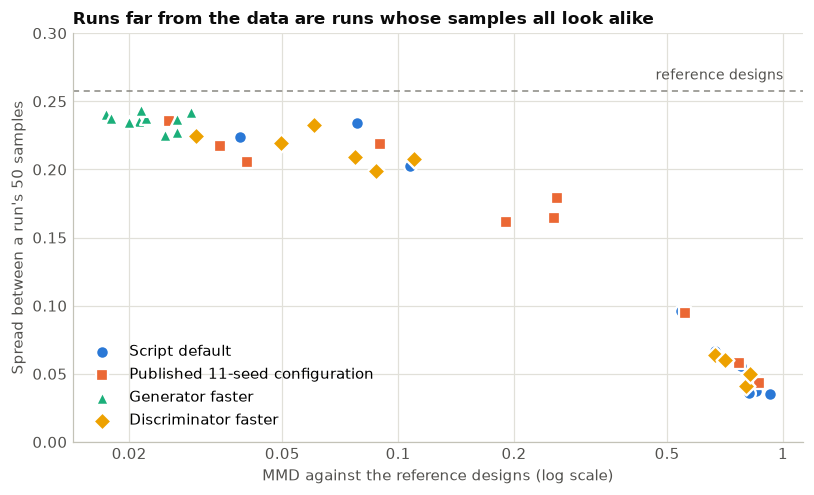

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for key, (label, _, _, colour, marker) in ARMS.items():
    part = runs[runs["key"] == key]
    ax.scatter(part["mmd"], part["sample_spread"], s=70, color=colour, marker=marker, edgecolor="white", linewidth=1.5, label=label, zorder=3)
ax.axhline(REF_SPREAD, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
ax.text(1.0, REF_SPREAD + 0.006, "reference designs", color=INK_2, ha="right", va="bottom", fontsize=9)
ax.set_xscale("log")
ax.set_xticks([0.02, 0.05, 0.1, 0.2, 0.5, 1.0])
ax.set_xticklabels(["0.02", "0.05", "0.1", "0.2", "0.5", "1"])
ax.minorticks_off()
ax.set_ylim(0, 0.3)
ax.set_xlabel("MMD against the reference designs (log scale)")
ax.set_ylabel("Spread between a run's 50 samples")
ax.grid(True)
ax.tick_params(length=0)
ax.legend(loc="lower left")
ax.set_title("Runs far from the data are runs whose samples all look alike")
plt.tight_layout()
plt.show()

The runs fall into three groups, and the 0.1 threshold alone hides the difference between the last two.

In [11]:
COLLAPSE_SPREAD = REF_SPREAD / 2  # samples vary less than half as much as the reference designs
runs["outcome"] = np.select(
    [runs["sample_spread"] < COLLAPSE_SPREAD, runs["mmd"] > MMD_THRESHOLD],
    ["collapsed", "degraded"], default="good")
outcome = (runs.groupby(["arm", "outcome"]).size().unstack(fill_value=0)
           .reindex(index=ORDER, columns=["good", "degraded", "collapsed"], fill_value=0))
display(outcome)
print("MMD range per outcome:")
print(runs.groupby("outcome")["mmd"].agg(["min", "max", "size"]).loc[["good", "degraded", "collapsed"]].to_string())

outcome,good,degraded,collapsed
arm,,,
Script default,2,1,7
Published 11-seed configuration,4,3,3
Generator faster,10,0,0
Discriminator faster,5,1,4


MMD range per outcome:
            min   max  size
outcome                    
good      0.017 0.089    21
degraded  0.107 0.259     5
collapsed 0.542 0.924    14


- **Good**: MMD at or below 0.1.
- **Degraded**: MMD above 0.1 but the samples still vary. The two I looked at are recognisable beams with defects.
- **Collapsed**: the samples vary less than half as much as the reference designs. There is a clear gap: no run ends with MMD between 0.26 and 0.54.

The figure below shows the first 8 of the 50 scored samples for one or two runs from each group. Each column uses the same conditions. It is drawn by `code/samples.py` from the trained generators.

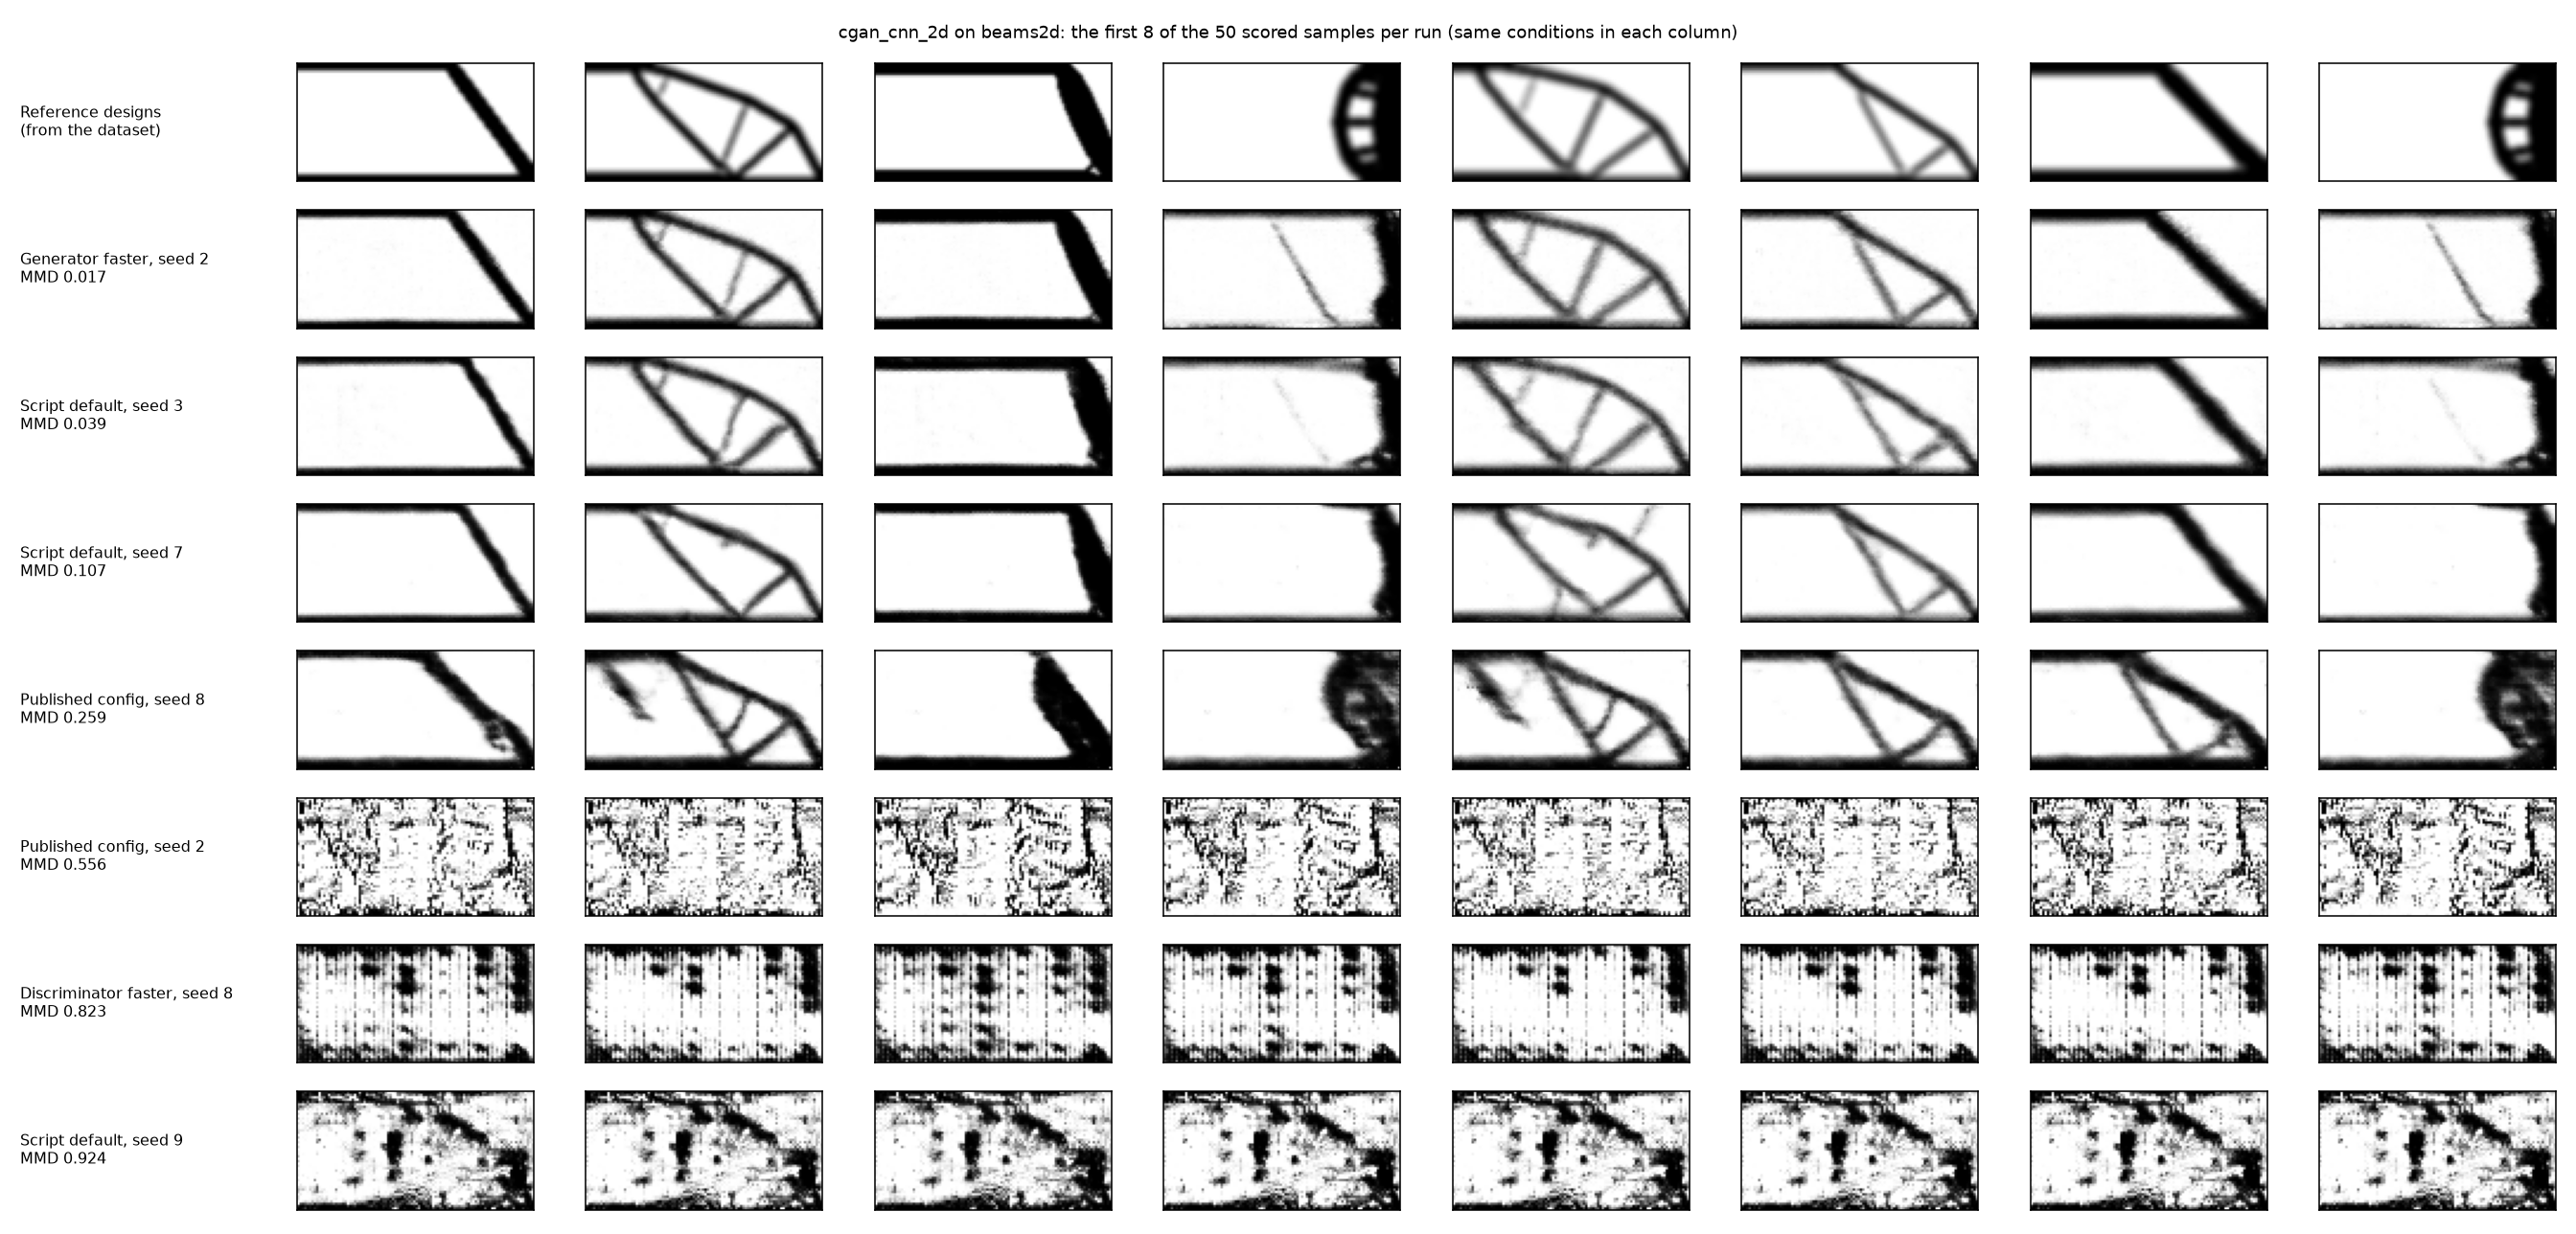

In [12]:
display(Image(filename="figures/samples.png", width=1100))

The collapsed runs shown draw a noisy texture instead of a beam, and it changes little from one condition to the next. It does not stay exactly the same: in some runs parts of the pattern still follow the conditions. The run just above the threshold (script default, seed 7, MMD 0.107) looks like the good ones, so the count of 8 of 10 for the script defaults is 7 collapsed runs plus one borderline run. The other borderline run (discriminator faster, seed 7, MMD 0.110) has a similar sample spread; I did not draw it.

The good runs are not perfect either. Columns 4 and 8 of the reference row show a design family that even the best generator does not reproduce.

### The violation rate stays noisy

The learning rates decide whether training collapses. They do not make the designs reliably feasible.

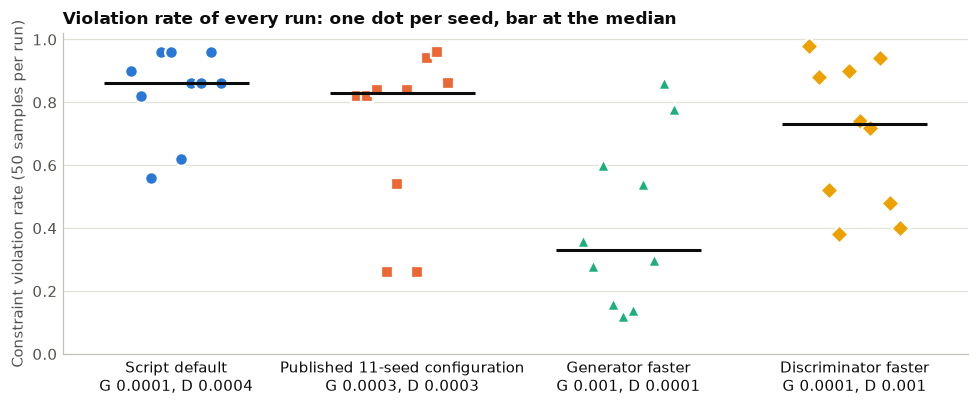

                                  min  median   max
arm                                                
Script default                  0.560   0.860 0.960
Published 11-seed configuration 0.260   0.830 0.960
Generator faster                0.120   0.330 0.860
Discriminator faster            0.380   0.730 0.980

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8))
strip(ax, "viol", "Constraint violation rate (50 samples per run)")
ax.set_ylim(0, 1.02)
ax.set_title("Violation rate of every run: one dot per seed, bar at the median")
plt.tight_layout()
plt.show()
print(runs.groupby("arm")["viol"].agg(["min", "median", "max"]).loc[ORDER].to_string())

In the generator-faster arm, where every seed matches the data distribution closely, the violation rate still runs from 0.12 to 0.86. With 50 samples per run each rate is itself coarse (one sample is 0.02), but the range is far wider than that.

## What I take from this

- For this baseline on this problem, a single-seed number is not enough to compare configurations. Ten seeds are cheap here, because one run takes minutes.
- Changing the two default learning rates to generator 1e-3 and discriminator 1e-4 removes the collapse in these runs. It is a two-number change to the script.
- MMD and the violation rate tell different stories. A run can match the data distribution well and still violate the constraints most of the time, so a stable baseline is a starting point for the feasibility question, not an answer to it.

## Limits

- One model and one problem. I have not checked whether the same pattern holds for the other baselines or for `heatconduction2d`, `photonics2d` or `thermoelastic2d`.
- Ten seeds per arm. The differences from the generator-faster arm are large, but the differences among the other three arms are not established.
- The 0.1 threshold is my choice. It falls in the gap of the published 11-seed results, and two of my runs sit just above it while looking fine. The collapse criterion (spread below half the reference) is also my choice; the gap it sits in is wide.
- All runs use 200 epochs. I did not check whether a collapsed run recovers with longer training, or at which epoch it collapses.
- One run (script default, seed 5) stopped early for a reason I could not determine. I retrained it from scratch with the same settings and it completed.
- Part 1 is a reading of published numbers. I did not retrain those configurations.

## Reproducing

```bash
cd code
git clone https://github.com/IDEALLab/EngiOpt     # commit 7a98ba5, then install it into a virtual environment
python pull_published.py ../data/published_checkpoints.json   # part 1 data
bash sweep.sh                                     # part 2: 40 training runs into runs/, then results_<arm>.csv
mv results_*.csv ../data/
python sample_spread.py ../data/sample_spread.csv
python samples.py ../figures/samples.png
```

The scripts expect the `EngiOpt` clone and the `runs` folder next to them. `run_one.py` runs the EngiOpt training script unchanged for one arm and seed and saves the generator weights in the layout `engiopt.evaluate` reads. The 40 trained generators are about 100 MB in total and I can share them.